# TICKET MJD-605
De: Íñigo Sainz · Director comercial
Para la reunión del comité: un gráfico de las ventas mensuales por canal, de 2024 a hoy, que se entien‐
da sin explicarlo. En imagen, que lo pego en la presentación.

ENTREGABLE
- entregables/mjd-605_ventas_canal.png.

In [5]:
import os, sys
from pathlib import Path

RAIZ = Path.home() / "master-data-ia"
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

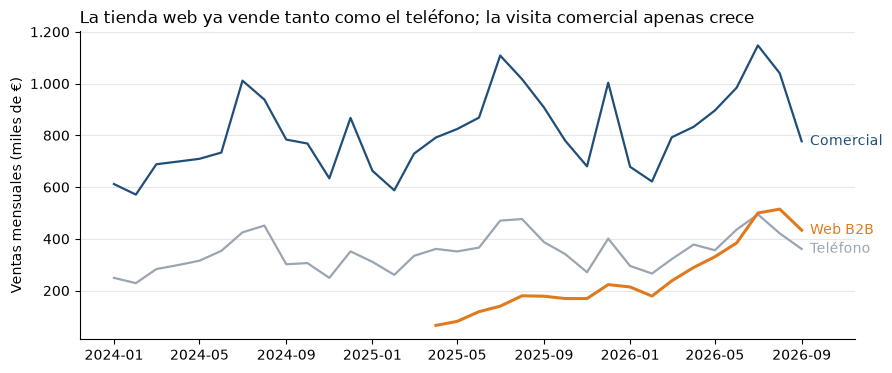

In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import duckdb
import pandas as pd

con = duckdb.connect("db/marejada.duckdb", read_only=True)
canal = con.sql("""
SELECT d.inicio_mes AS mes, f.canal, sum(f.importe_neto) / 1000 AS miles
FROM gold.fact_ventas AS f
JOIN gold.dim_fecha AS d ON d.fecha_key = f.fecha_key
GROUP BY ALL
""").df().pivot_table(index="mes", columns="canal", values="miles")
con.close()

colores = {"Comercial": "#1f4e79", "Teléfono": "#9aa5b1", "Web B2B": "#e07a1f"}
fig, ax = plt.subplots(figsize=(10, 4))
for c in canal.columns:
    ax.plot(canal.index, canal[c], label=c, color=colores[c], linewidth=2.2 if c == "Web B2B" else 1.6)
    ax.annotate(c, (canal.index[-1], canal[c].iloc[-1]), xytext=(6, 0),
        textcoords="offset points", va="center", color=colores[c])

ax.set_title("La tienda web ya vende tanto como el teléfono; la visita comercial apenas crece",
    loc="left", fontsize=12)
ax.set_ylabel("Ventas mensuales (miles de €)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_xlim(right=canal.index[-1] + pd.Timedelta(days=75))
fig.savefig("entregables/mjd-605_ventas_canal.png", dpi=150, bbox_inches="tight")
plt.show()

Antes de mandarlo, la segunda vía: ¿es verdad lo que dice el título? Enero a septiembre de cada año, en miles
de euros, y la variación:

In [7]:
ene_sep = canal[canal.index.month <= 9].groupby(canal.index[canal.index.month <= 9].year).sum()
print(ene_sep.round(0))
(ene_sep.pct_change() * 100).round(1)

canal  Comercial  Teléfono  Web B2B
mes                                
2024      6746.0    2907.0      0.0
2025      7498.0    3319.0    763.0
2026      7771.0    3329.0   3083.0


canal,Comercial,Teléfono,Web B2B
mes,,,
2024,NaN,NaN,NaN
2025,11.1,14.2,inf
2026,3.6,0.3,304.0


El título aguanta: de enero a septiembre, la visita comercial crece un 3,6 % y el teléfono un 0,3 %, mientras la
web se multiplica por cuatro (+304 %; el inf de 2025 es una división entre el cero de 2024). Y en julio, agos‐
to y septiembre de 2026 la web ya vendió más que el teléfono (500, 515 y 434 miles de euros, contra 495, 421
y 361).